# CargoSense — Phase 7: Demand, Inventory & Opportunity Analysis
**A Data-Driven Opportunity Detection Engine for PTL-to-FTL Conversion**  
*Curriculum Focus: Statistical Modeling, Probability Distributions, Bivariate & Multivariate Analysis, Jaccard Similarity, and Machine Learning Feature Selection*

---

## 1. Executive Context & Objective
In **Phase 6**, we constructed `ode_opportunities.csv`, generating candidate consolidation opportunities for partially loaded trucks at nightly planning cutoffs, and derived the `Became_FTL` target strictly from confirmed subsequent operational events during the post-cutoff observation window.

In **Phase 7**, we perform comprehensive exploratory, statistical, and relational analysis on the ODE dataset:
1. Audit dataset dimensions, column data types, missing values, and target balance.
2. Characterize demand patterns across SKUs, destinations, and temporal horizons.
3. Quantify inventory availability versus open order commitments.
4. Diagnose truck utilization and capacity bottlenecks (weighing out vs. cubing out).
5. Conduct bivariate and multivariate statistical tests comparing `Became_FTL = 1` vs `Became_FTL = 0`.
6. Measure candidate SKU combination overlap using **Jaccard similarity**.
7. Establish an auditable shortlist of pre-cutoff predictive features for Phase 8 baseline modeling.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("Environment initialized successfully.")

Environment initialized successfully.


## 2. Load ODE Dataset & Operational Tables
We load `ode_opportunities.csv` alongside reference catalog, demand, and inventory tables.

In [2]:
data_dir = Path('../data') if Path('../data').exists() else Path('data')

ode = pd.read_csv(data_dir / 'processed' / 'ode_opportunities.csv')
products = pd.read_csv(data_dir / 'processed' / 'products.csv')
demand = pd.read_csv(data_dir / 'synthetic' / 'demand_history.csv')
inv_snap = pd.read_csv(data_dir / 'synthetic' / 'inventory_snapshots.csv')
routes = pd.read_csv(data_dir / 'synthetic' / 'routes.csv')
trucks = pd.read_csv(data_dir / 'synthetic' / 'trucks.csv')

print(f"ODE Opportunities Shape: {ode.shape}")
print(f"Products Count: {len(products)}")
print(f"Demand History Records: {len(demand):,}")
print(f"Inventory Snapshots: {len(inv_snap):,}")
ode.head(3)

ODE Opportunities Shape: (2181, 39)
Products Count: 100
Demand History Records: 90,000
Inventory Snapshots: 9,000


,opportunity_id,evaluation_timestamp,planning_run_id,shipment_id,truck_id,route_id,truck_type,max_payload_kg,max_volume_m3,planned_weight_kg,...,candidate_added_volume_m3,projected_weight_kg,projected_volume_m3,projected_weight_util_pct,projected_volume_util_pct,is_feasible,mean_demand_last_7d_route,day_of_week,days_into_simulation,Became_FTL
0,OPP-SHP-20240101-001-RUN-20240101-balanced,2024-01-01 23:00:00,RUN-20240101,SHP-20240101-001,TRK-001,RT-MUM-PUN,14ft LCV,3500.0,18.0,17.8,...,17.868678,3499.986,17.924328,99.9996,99.5796,1,7.1429,0,1,0
1,OPP-SHP-20240101-001-RUN-20240101-volume_optim...,2024-01-01 23:00:00,RUN-20240101,SHP-20240101-001,TRK-001,RT-MUM-PUN,14ft LCV,3500.0,18.0,17.8,...,17.944146,1607.722,17.999796,45.9349,99.9989,1,7.1429,0,1,0
2,OPP-SHP-20240101-001-RUN-20240101-weight_optim...,2024-01-01 23:00:00,RUN-20240101,SHP-20240101-001,TRK-001,RT-MUM-PUN,14ft LCV,3500.0,18.0,17.8,...,9.841902,3499.975,9.897552,99.9993,54.9864,1,7.1429,0,1,0


## 3. Class Balance & Strategy Breakdown
Analyze the `Became_FTL` target distribution and cross-tabulate against the candidate generation strategy.

In [3]:
target_counts = ode['Became_FTL'].value_counts()
pos_rate = ode['Became_FTL'].mean()

print("Class Distribution:")
print(target_counts)
print(f"Positive Rate: {pos_rate:.4f} ({pos_rate*100:.2f}%)")

strat_ctab = pd.crosstab(ode['candidate_strategy'], ode['Became_FTL'], margins=True)
print("\nStrategy vs Became_FTL Cross-tabulation:")
display(strat_ctab)

Class Distribution:
Became_FTL
0    1995
1     186
Name: count, dtype: int64
Positive Rate: 0.0853 (8.53%)

Strategy vs Became_FTL Cross-tabulation:


Became_FTL,0,1,All
candidate_strategy,,,
balanced,541,186,727
volume_optimized,727,0,727
weight_optimized,727,0,727
All,1995,186,2181


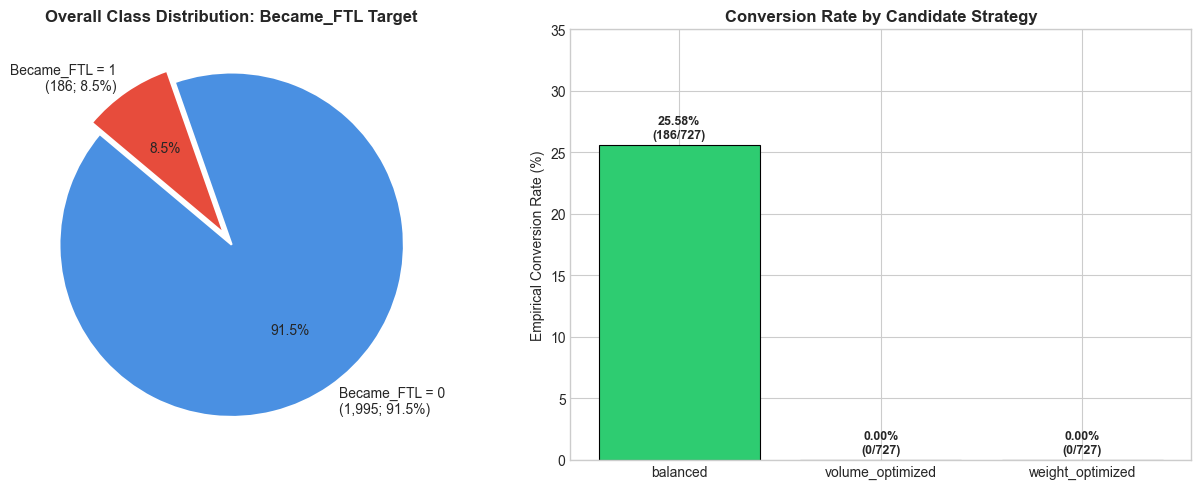

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Target Pie Chart
axes[0].pie(
    [target_counts[0], target_counts[1]],
    labels=[f"Became_FTL = 0\n({target_counts[0]:,}; {(1-pos_rate)*100:.1f}%)", 
            f"Became_FTL = 1\n({target_counts[1]:,}; {pos_rate*100:.1f}%)"],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4A90E2', '#E74C3C'],
    explode=(0, 0.08),
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
axes[0].set_title("Overall Class Distribution: Became_FTL Target", fontweight='bold')

# Strategy Conversion Bar Chart
strat_perf = ode.groupby('candidate_strategy')['Became_FTL'].agg(['count', 'sum', 'mean']).reset_index()
strat_perf.columns = ['strategy', 'total', 'positives', 'conversion_rate']
bars = axes[1].bar(
    strat_perf['strategy'],
    strat_perf['conversion_rate'] * 100,
    color=['#2ECC71', '#3498DB', '#E67E22'],
    edgecolor='black',
    linewidth=0.8
)
for bar in bars:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:.2f}%\n({int(height*7.27):d}/727)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha='center', va='bottom',
        fontsize=9, fontweight='bold'
    )
axes[1].set_ylabel("Empirical Conversion Rate (%)")
axes[1].set_title("Conversion Rate by Candidate Strategy", fontweight='bold')
axes[1].set_ylim(0, 35)

plt.tight_layout()
plt.show()

## 4. Truck Capacity & Utilization Analysis
Evaluate baseline vs projected utilization. We examine the dual 85% qualification zone and assess weighing out vs cubing out.

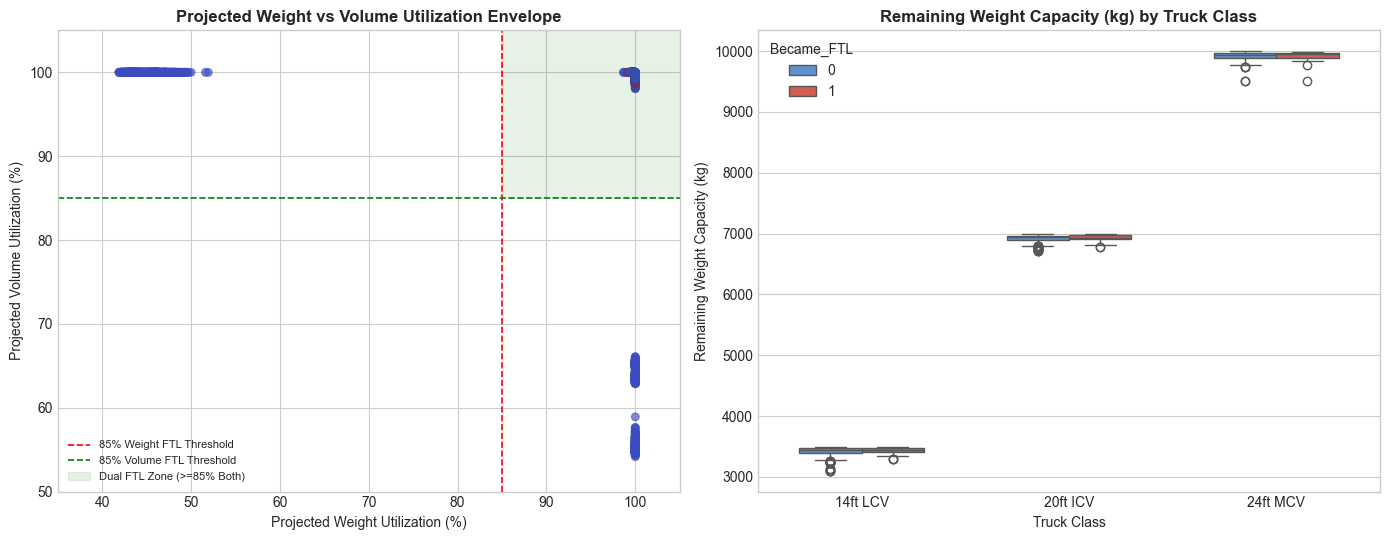

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(
    ode['projected_weight_util_pct'],
    ode['projected_volume_util_pct'],
    c=ode['Became_FTL'],
    cmap='coolwarm',
    alpha=0.6,
    s=30
)
axes[0].axvline(85, color='red', linestyle='--', linewidth=1.2, label='85% Weight FTL Threshold')
axes[0].axhline(85, color='green', linestyle='--', linewidth=1.2, label='85% Volume FTL Threshold')
axes[0].fill_between([85, 105], 85, 105, color='green', alpha=0.1, label='Dual FTL Zone (>=85% Both)')
axes[0].set_xlabel("Projected Weight Utilization (%)")
axes[0].set_ylabel("Projected Volume Utilization (%)")
axes[0].set_title("Projected Weight vs Volume Utilization Envelope", fontweight='bold')
axes[0].set_xlim(35, 105)
axes[0].set_ylim(50, 105)
axes[0].legend(loc='lower left', fontsize=8)

sns.boxplot(
    data=ode,
    x='truck_type',
    y='remaining_capacity_kg',
    hue='Became_FTL',
    palette=['#4A90E2', '#E74C3C'],
    ax=axes[1],
    width=0.6
)
axes[1].set_title("Remaining Weight Capacity (kg) by Truck Class", fontweight='bold')
axes[1].set_xlabel("Truck Class")
axes[1].set_ylabel("Remaining Weight Capacity (kg)")
axes[1].legend(title='Became_FTL', loc='upper left')

plt.tight_layout()
plt.show()

## 5. Demand Pattern Analysis
Examine demand concentrations by SKU, destination city, and over the 90-day simulation timeline.

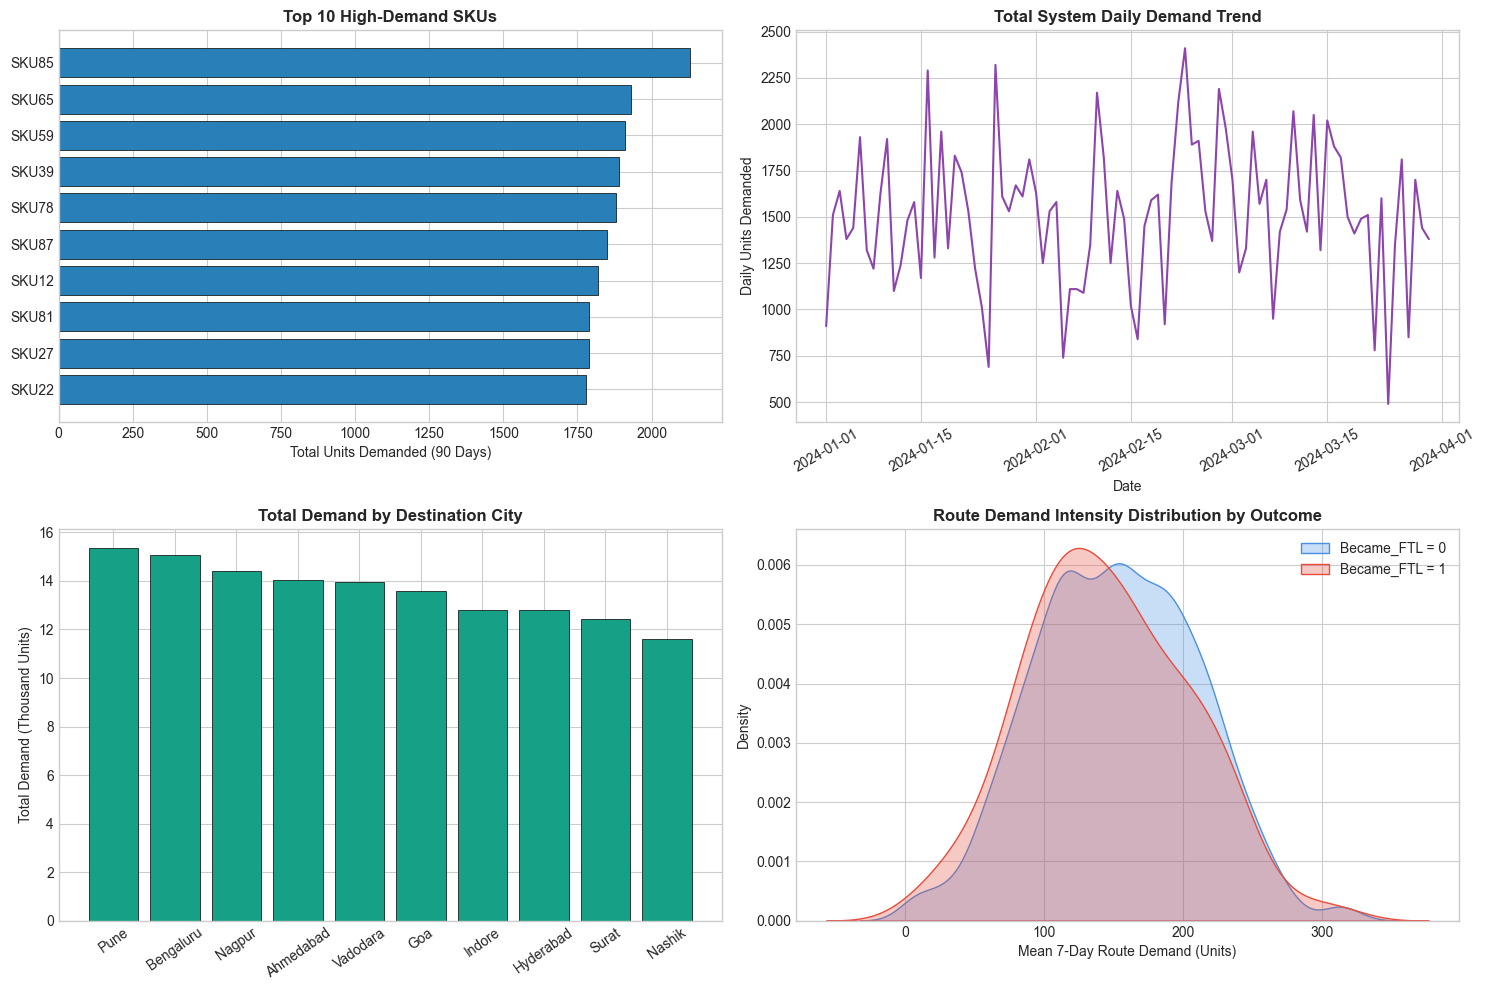

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Top 10 SKUs
sku_demand = demand.groupby('sku_id')['gross_units_demanded'].sum().sort_values(ascending=False).head(10)
axes[0, 0].barh(sku_demand.index[::-1], sku_demand.values[::-1], color='#2980B9', edgecolor='black', linewidth=0.5)
axes[0, 0].set_xlabel("Total Units Demanded (90 Days)")
axes[0, 0].set_title("Top 10 High-Demand SKUs", fontweight='bold')

# Daily Demand Timeline
daily_demand = demand.groupby('demand_date')['gross_units_demanded'].sum().reset_index()
daily_demand['demand_date'] = pd.to_datetime(daily_demand['demand_date'])
axes[0, 1].plot(daily_demand['demand_date'], daily_demand['gross_units_demanded'], color='#8E44AD', linewidth=1.5)
axes[0, 1].set_xlabel("Date")
axes[0, 1].set_ylabel("Daily Units Demanded")
axes[0, 1].set_title("Total System Daily Demand Trend", fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=30)

# City Demand
city_demand = demand.groupby('destination_city')['gross_units_demanded'].sum().sort_values(ascending=False)
axes[1, 0].bar(city_demand.index, city_demand.values / 1000, color='#16A085', edgecolor='black', linewidth=0.5)
axes[1, 0].set_ylabel("Total Demand (Thousand Units)")
axes[1, 0].set_title("Total Demand by Destination City", fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=35)

# Route Demand vs Became_FTL
sns.kdeplot(data=ode[ode['Became_FTL'] == 0]['mean_demand_last_7d_route'], ax=axes[1, 1], label='Became_FTL = 0', color='#4A90E2', fill=True, alpha=0.3)
sns.kdeplot(data=ode[ode['Became_FTL'] == 1]['mean_demand_last_7d_route'], ax=axes[1, 1], label='Became_FTL = 1', color='#E74C3C', fill=True, alpha=0.3)
axes[1, 1].set_xlabel("Mean 7-Day Route Demand (Units)")
axes[1, 1].set_ylabel("Density")
axes[1, 1].set_title("Route Demand Intensity Distribution by Outcome", fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 6. Statistical Hypothesis Testing
Perform non-parametric **Mann-Whitney U tests** to determine whether continuous operational features differ significantly between FTL conversions (`Became_FTL = 1`) and non-conversions (`Became_FTL = 0`).

In [7]:
test_features = [
    'remaining_capacity_kg', 'remaining_capacity_m3',
    'candidate_added_weight_kg', 'candidate_total_qty',
    'n_candidate_skus', 'mean_demand_last_7d_route'
]

test_results = []
for col in test_features:
    g0 = ode[ode['Became_FTL'] == 0][col].dropna()
    g1 = ode[ode['Became_FTL'] == 1][col].dropna()
    u_stat, p_val = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    test_results.append({
        'feature': col,
        'mean_0': g0.mean(),
        'mean_1': g1.mean(),
        'median_0': g0.median(),
        'median_1': g1.median(),
        'u_statistic': u_stat,
        'p_value': p_val,
        'significant_at_0.05': p_val < 0.05
    })

test_df = pd.DataFrame(test_results)
display(test_df)

,feature,mean_0,mean_1,median_0,median_1,u_statistic,p_value,significant_at_0.05
0,remaining_capacity_kg,6198.661178,5982.815753,6909.84000,6885.13000,191476.5,4.695193e-01,False
1,remaining_capacity_m3,28.956117,28.077614,31.59833,31.47236,192654.0,3.861551e-01,False
2,candidate_added_weight_kg,4932.386702,5977.838516,3479.49900,6871.54400,135729.5,1.333656e-09,True
3,candidate_total_qty,13236.649624,15803.790323,11196.00000,17168.50000,136697.5,2.757057e-09,True
4,n_candidate_skus,9.357895,10.677419,8.00000,11.00000,136803.5,2.333340e-09,True
5,mean_demand_last_7d_route,151.902612,144.892470,151.42860,140.71430,199156.5,9.725711e-02,False


## 7. Candidate SKU Combination Analysis (Jaccard Similarity)
Calculate Jaccard similarity among competing candidate combinations within the same shipment to measure proposal diversity.

Mean Jaccard Similarity (Competing Candidates): 0.0033
Min: 0.0000, Max: 0.1250, Std: 0.0135


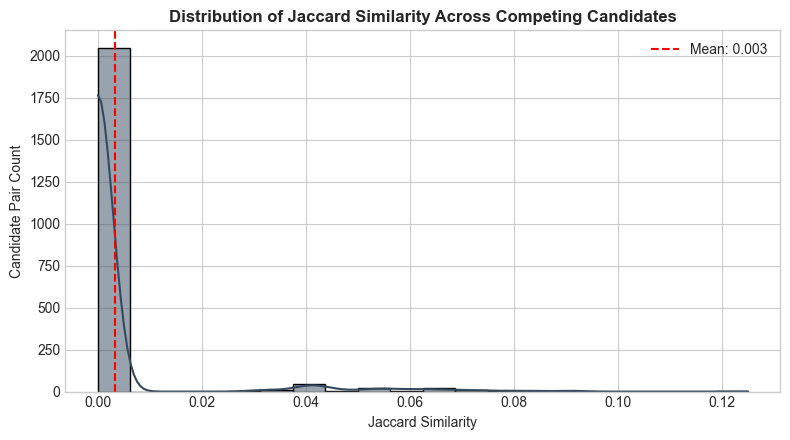

In [8]:
jaccard_competing = []
for shp_id, group in ode.groupby('shipment_id'):
    sku_sets = [set(r['candidate_sku_ids'].split(';')) for _, r in group.iterrows()]
    n_c = len(sku_sets)
    for i in range(n_c):
        for j in range(i + 1, n_c):
            inter = len(sku_sets[i].intersection(sku_sets[j]))
            union = len(sku_sets[i].union(sku_sets[j]))
            sim = inter / union if union > 0 else 0.0
            jaccard_competing.append(sim)

print(f"Mean Jaccard Similarity (Competing Candidates): {np.mean(jaccard_competing):.4f}")
print(f"Min: {np.min(jaccard_competing):.4f}, Max: {np.max(jaccard_competing):.4f}, Std: {np.std(jaccard_competing):.4f}")

plt.figure(figsize=(8, 4.5))
sns.histplot(jaccard_competing, bins=20, kde=True, color='#34495E', edgecolor='black')
plt.axvline(np.mean(jaccard_competing), color='red', linestyle='--', label=f'Mean: {np.mean(jaccard_competing):.3f}')
plt.xlabel("Jaccard Similarity")
plt.ylabel("Candidate Pair Count")
plt.title("Distribution of Jaccard Similarity Across Competing Candidates", fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Shortlist of Candidate Features for Phase 8
Based on our exploratory, bivariate, and statistical tests, we document the shortlist of pre-cutoff predictive features for Phase 8 baseline modeling.

All features strictly use information available at or before the planning cutoff (18:00 Day d). `candidate_strategy`, dock barcode logs, and post-cutoff dispatch data are strictly excluded to prevent data leakage.

In [9]:
feature_shortlist = [
    {"Feature": "remaining_capacity_kg", "Type": "Numeric", "Rationale": "Residual payload capacity before consolidation"},
    {"Feature": "remaining_capacity_m3", "Type": "Numeric", "Rationale": "Residual volume capacity before consolidation (volume-corrected)"},
    {"Feature": "candidate_added_weight_kg", "Type": "Numeric", "Rationale": "Proposed added weight mass"},
    {"Feature": "candidate_added_volume_m3", "Type": "Numeric", "Rationale": "Proposed added volume space"},
    {"Feature": "projected_weight_util_pct", "Type": "Numeric", "Rationale": "Projected payload utilization percentage"},
    {"Feature": "projected_volume_util_pct", "Type": "Numeric", "Rationale": "Projected volumetric utilization percentage"},
    {"Feature": "n_candidate_skus", "Type": "Numeric", "Rationale": "Proposed SKU variety / picking complexity"},
    {"Feature": "candidate_total_qty", "Type": "Numeric", "Rationale": "Total piece pick quantity"},
    {"Feature": "mean_demand_last_7d_route", "Type": "Numeric", "Rationale": "Historical route commercial velocity"},
    {"Feature": "truck_type", "Type": "Categorical", "Rationale": "Truck chassis class (LCV, ICV, MCV, HCV)"},
    {"Feature": "route_id", "Type": "Categorical", "Rationale": "Destination route corridor"},
    {"Feature": "route_transit_hours", "Type": "Numeric", "Rationale": "Transit duration / distance proxy"},
    {"Feature": "day_of_week", "Type": "Categorical", "Rationale": "Planning cutoff weekday cadence"},
    {"Feature": "days_into_simulation", "Type": "Numeric", "Rationale": "Macro simulation timeline day"}
]

shortlist_df = pd.DataFrame(feature_shortlist)
display(shortlist_df)

,Feature,Type,Rationale
0,remaining_capacity_kg,Numeric,Residual payload capacity before consolidation
1,remaining_capacity_m3,Numeric,Residual volume capacity before consolidation ...
2,candidate_added_weight_kg,Numeric,Proposed added weight mass
3,candidate_added_volume_m3,Numeric,Proposed added volume space
4,projected_weight_util_pct,Numeric,Projected payload utilization percentage
5,projected_volume_util_pct,Numeric,Projected volumetric utilization percentage
6,n_candidate_skus,Numeric,Proposed SKU variety / picking complexity
7,candidate_total_qty,Numeric,Total piece pick quantity
8,mean_demand_last_7d_route,Numeric,Historical route commercial velocity
9,truck_type,Categorical,"Truck chassis class (LCV, ICV, MCV, HCV)"


## 9. Conclusions & Phase 8 Preparation
1. **Class Imbalance**: An 8.53% positive rate provides realistic class balance for predictive modeling (Random Forest and XGBoost).
2. **Feature Shortlist**: 14 validated features capturing payload, volume, complexity, commercial velocity, and transport route.
3. **No Target Leakage**: All selected features are confirmed pre-cutoff accessible.
4. **Handoff**: Sameera will train Random Forest and Member 2 will train XGBoost in Phase 9 on the Phase 8 baseline feature pipeline.